# Clase 1 — Simulación de símbolos LoRa mediante chirps

En este notebook generamos símbolos LoRa, observamos su parte real, imaginaria y frecuencia instantánea, y luego recuperamos el símbolo con *dechirp* y una FFT.

Ejecutá las celdas de arriba hacia abajo con `Shift + Enter`.

## Etapa 1 — Importar librerías y fijar parámetros

Usamos `numpy` para los cálculos numéricos y `matplotlib` para las gráficas. El ancho de banda se fija en 125 kHz.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

B = 125_000  # ancho de banda [Hz]
MAX_SIMBOLOS = 5
MUESTRAS_POR_MUESTRA = 16  # suaviza la vista temporal


## Etapa 2 — Definir la trama y validar la entrada

Cada símbolo se escribe como una cadena binaria. Su cantidad de bits determina el *spreading factor* (`SF`). Por ejemplo, `00100101` tiene 8 bits, así que `SF = 8` y hay $N = 2^{SF} = 256$ valores de símbolo posibles.

La función siguiente verifica que todos los símbolos tengan la misma longitud y solo contengan ceros y unos.

In [2]:
simbolos = ["00100101"]
# Para probar una trama más larga, descomentá esta línea:
# simbolos = ["00100101", "11110000", "00000011"]

def validar_simbolos(simbolos):
    if not isinstance(simbolos, (list, tuple)):
        raise TypeError("simbolos debe ser una lista o tupla de cadenas binarias")
    if not 1 <= len(simbolos) <= MAX_SIMBOLOS:
        raise ValueError(f"se admiten entre 1 y {MAX_SIMBOLOS} simbolos")
    if not all(isinstance(bits, str) and set(bits) <= {"0", "1"} for bits in simbolos):
        raise ValueError("cada simbolo debe ser una cadena formada solo por '0' y '1'")

    sf = len(simbolos[0])
    if sf == 0 or any(len(bits) != sf for bits in simbolos):
        raise ValueError("todos los simbolos deben tener la misma longitud y al menos un bit")
    return sf

sf = validar_simbolos(simbolos)
N = 2**sf
Ts = N / B
print(f"SF={sf}, N={N}, duración de símbolo Ts={Ts * 1e3:.3f} ms")


SF=8, N=256, duración de símbolo Ts=2.048 ms


## Etapa 3 — Construir la fase y el chirp

Un chirp LoRa recorre una frecuencia en forma de sierra. `fase_sierra` integra esa frecuencia para obtener una fase continua, útil para mostrar la onda en el tiempo. `modular_simbolo` genera además la versión discreta que se procesa con la FFT.

In [3]:
def fase_sierra(tiempo, valor, N):
    """Fase continua cuya derivada es la sierra de frecuencia del chirp."""
    indice = valor + 2 * B * tiempo
    ciclos_completos = np.floor(indice / N)
    resto = np.mod(indice, N)
    area_de_sierra = (ciclos_completos * N**2 + resto**2) / 2
    return (area_de_sierra - valor**2 / 2) / (2 * N)

def modular_simbolo(valor, k, N):
    """Genera el chirp discreto y una vista temporal sobreamostrada."""
    # Ecuación (3): muestras usadas por el modulador y la FFT.
    fase_discreta = ((valor + k) % N) * k / N
    chirp = np.exp(1j * 2 * np.pi * fase_discreta) / np.sqrt(N)

    tiempo_vista = np.linspace(0, Ts, N * MUESTRAS_POR_MUESTRA + 1)
    frecuencia_vista = np.mod(valor + 2 * B * tiempo_vista, N) * B / N
    fase = 2 * np.pi * fase_sierra(tiempo_vista, valor, N)
    real = np.cos(fase) / np.sqrt(N)
    imaginaria = np.sin(fase) / np.sqrt(N)
    return chirp, tiempo_vista, real, imaginaria, frecuencia_vista


## Etapa 4 — Modular y detectar con dechirp + FFT

Primero convertimos cada cadena binaria a su valor decimal. Para detectarlo, multiplicamos el chirp recibido por un *downchirp* y calculamos la FFT. El índice del pico máximo corresponde al símbolo transmitido.

In [4]:
k = np.arange(N)
downchirp = np.exp(-1j * 2 * np.pi * k**2 / N)
valores_enviados = [int(bits, 2) for bits in simbolos]
valores_estimados = []
vistas = []

for valor in valores_enviados:
    chirp, tiempo, real, imaginaria, frecuencia = modular_simbolo(valor, k, N)
    vistas.append((tiempo, real, imaginaria, frecuencia))

    espectro = np.abs(np.fft.fft(chirp * downchirp))
    valores_estimados.append(int(np.argmax(espectro)))

assert valores_estimados == valores_enviados
for bits, enviado, estimado in zip(simbolos, valores_enviados, valores_estimados):
    print(f"{bits} → s={enviado}; detectado={estimado}")


00100101 → s=37; detectado=37


## Etapa 5 — Visualizar el resultado

Las dos primeras gráficas muestran las componentes real e imaginaria del chirp. La tercera muestra su frecuencia instantánea. Si agregás más símbolos en la etapa 2, las líneas punteadas separan la duración de cada uno.

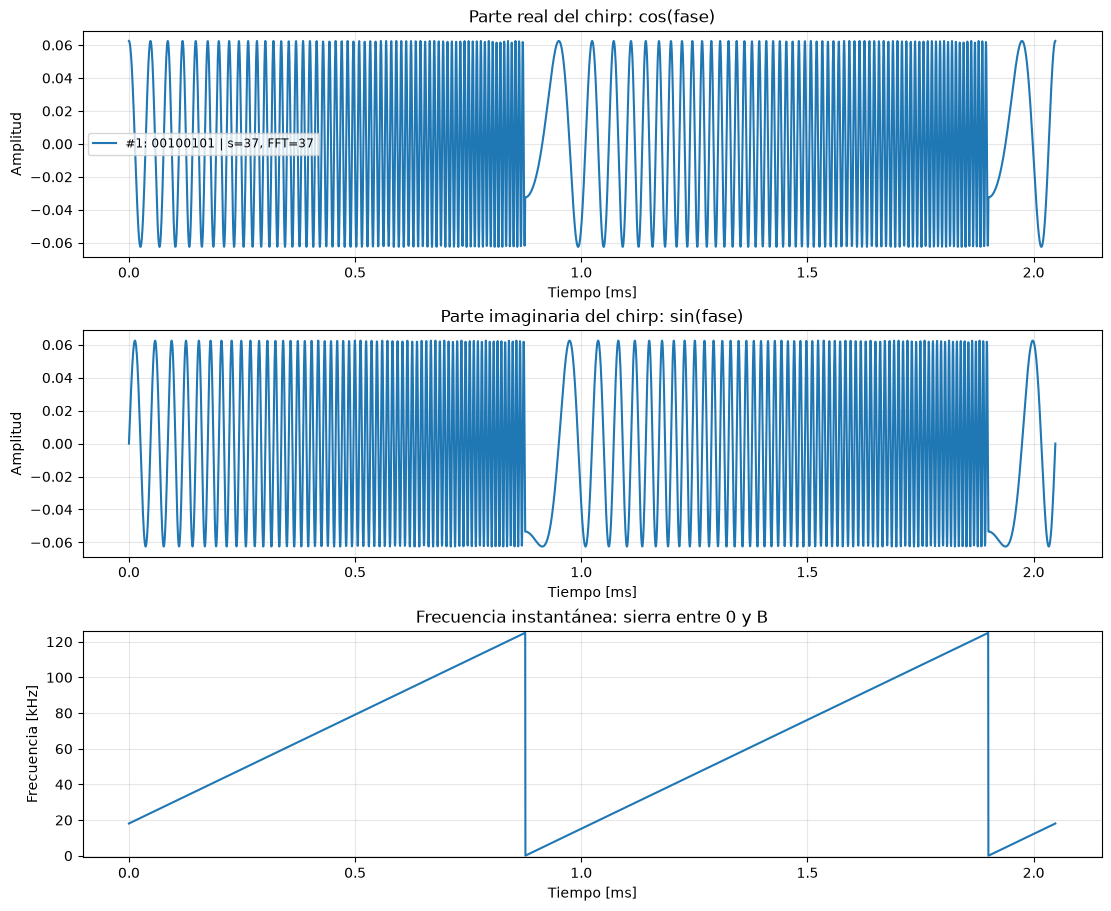

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(11, 9), constrained_layout=True)

for indice, ((tiempo, real, imaginaria, frecuencia), bits, enviado, estimado) in enumerate(
    zip(vistas, simbolos, valores_enviados, valores_estimados)
):
    tiempo = indice * Ts + tiempo
    etiqueta = f"#{indice + 1}: {bits} | s={enviado}, FFT={estimado}"
    axes[0].plot(tiempo * 1e3, real, label=etiqueta)
    axes[1].plot(tiempo * 1e3, imaginaria, label=etiqueta)
    axes[2].plot(tiempo * 1e3, frecuencia / 1e3)

limites_ms = np.arange(len(vistas) + 1) * Ts * 1e3
for limite in limites_ms[1:-1]:
    for ax in axes:
        ax.axvline(limite, color="gray", linestyle="--", alpha=0.6)

axes[0].set(title="Parte real del chirp: cos(fase)", xlabel="Tiempo [ms]", ylabel="Amplitud")
axes[1].set(title="Parte imaginaria del chirp: sin(fase)", xlabel="Tiempo [ms]", ylabel="Amplitud")
axes[2].set(title="Frecuencia instantánea: sierra entre 0 y B", xlabel="Tiempo [ms]", ylabel="Frecuencia [kHz]")
axes[2].set_ylim(-1, B / 1e3 + 1)

for ax in axes:
    ax.grid(True, alpha=0.3)
axes[0].legend(ncol=min(len(vistas), 3), fontsize="small")
plt.show()


## Para experimentar

Volvé a la etapa 2 y probá con dos o tres símbolos de 8 bits. También podés cambiar el valor de `B` y observar cómo cambia $T_s=N/B$. Todos los símbolos de una misma simulación deben tener la misma cantidad de bits.